In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pickle
import math
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import pyBigWig

In [2]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle1_CT20220323.npz'
np_file = np.load(filename)
cycle1_dhs_arr = np_file['new_dhs_array']

cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [3]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

biosample_df['Replicate indicators'] = biosample_df['Replicate indicators'].astype(str)

In [4]:
#find replicates
biosamples_repnames = np.array(biosample_df['Replicate indicators'])
biosamples_sampnames = np.array(biosample_df['Altius Biosample ID'])

In [5]:
cycle0_dhs_int_arr = cycle0_dhs_arr.astype(int)
cycle1_dhs_int_arr = cycle1_dhs_arr.astype(int)

In [6]:
biosample_df['index'] = biosample_df.index
biosample_altbioid_df = biosample_df.set_index(['Altius Biosample ID'])

In [9]:
n_biosamples, n_DHSs = cycle0_dhs_int_arr.shape

In [31]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [39]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1


In [18]:
#newer function that accounts for pairings with multiple replicates
def test_similarity2(dhs_arr, repnames_arr=biosamples_repnames, sampnames_arr=biosamples_sampnames):
    sample_pairings = []
    for rep_name, rep_ind, samp_name in zip(repnames_arr, range(len(repnames_arr)), sampnames_arr):
        if (rep_name!='nan'):
            rep_list = rep_name.split(',')
            rep_list.append(samp_name)
            pairing_filtered = []
            for rep in rep_list:
                if rep in sampnames_arr:
                    pairing_filtered.append(rep)
            pairing_filtered = np.array(pairing_filtered)
            if len(pairing_filtered) > 1:
                pairing_ind_sorted = tuple(np.sort(biosample_altbioid_df.loc[pairing_filtered]['index']))
                if pairing_ind_sorted not in sample_pairings:
                    sample_pairings.append(pairing_ind_sorted)
    
    total_changes = []
    total_num_dhss = []
    total_min_spot =[]
    dhs_diff_counter = np.zeros(n_DHSs).astype(int)
    for pairing in sample_pairings:
        if len(pairing)==2:
            num_dhss = np.mean([np.sum(dhs_arr[pairing[0], :]), np.sum(dhs_arr[pairing[1], :])])
            changes = np.abs(dhs_arr[pairing[0], :] - dhs_arr[pairing[1], :])
            dhs_diff_counter[np.where(changes==1)[0]]+=1
            changes = np.sum(changes)
        elif len(pairing)==3:
            num_dhss = np.mean([np.sum(dhs_arr[pairing[0], :]), np.sum(dhs_arr[pairing[1], :]), 
                                np.sum(dhs_arr[pairing[2], :])])
            changes1 = np.abs(dhs_arr[pairing[0], :] - dhs_arr[pairing[1], :])
            dhs_diff_counter[np.where(changes1==1)[0]]+=1
            changes2 = np.abs(dhs_arr[pairing[1], :] - dhs_arr[pairing[2], :])
            dhs_diff_counter[np.where(changes2==1)[0]]+=1
            changes3 = np.abs(dhs_arr[pairing[2], :] - dhs_arr[pairing[0], :])
            dhs_diff_counter[np.where(changes3==1)[0]]+=1
            changes = np.mean([np.sum(changes1), np.sum(changes2), np.sum(changes3)])
        elif len(pairing)==4:
            num_dhss = np.mean([np.sum(dhs_arr[pairing[0], :]), np.sum(dhs_arr[pairing[1], :]), 
                                np.sum(dhs_arr[pairing[2], :]), np.sum(dhs_arr[pairing[3], :])])
            changes1 = np.abs(dhs_arr[pairing[0], :] - dhs_arr[pairing[1], :])
            dhs_diff_counter[np.where(changes1==1)[0]]+=1
            changes2 = np.abs(dhs_arr[pairing[1], :] - dhs_arr[pairing[2], :])
            dhs_diff_counter[np.where(changes2==1)[0]]+=1
            changes3 = np.abs(dhs_arr[pairing[2], :] - dhs_arr[pairing[3], :])
            dhs_diff_counter[np.where(changes3==1)[0]]+=1
            changes4 = np.abs(dhs_arr[pairing[3], :] - dhs_arr[pairing[0], :])
            dhs_diff_counter[np.where(changes4==1)[0]]+=1
            changes5 = np.abs(dhs_arr[pairing[0], :] - dhs_arr[pairing[2], :])
            dhs_diff_counter[np.where(changes5==1)[0]]+=1
            changes6 = np.abs(dhs_arr[pairing[1], :] - dhs_arr[pairing[3], :])
            dhs_diff_counter[np.where(changes6==1)[0]]+=1
            changes = np.mean([np.sum(changes1), np.sum(changes2), np.sum(changes3), np.sum(changes4),
                               np.sum(changes5), np.sum(changes6)])
        total_changes.append(changes)
        total_num_dhss.append(num_dhss)
        total_min_spot.append(np.min(biosample_df.loc[np.array(pairing)]['DCC SPOT score']))
    total_changes = np.array(total_changes)
    total_num_dhss = np.array(total_num_dhss)
    total_min_spot = np.array(total_min_spot)
    
    average_changes = np.mean(total_changes)
    print(average_changes)
    return total_changes, total_num_dhss, total_min_spot, sample_pairings, dhs_diff_counter

cycle0_total_changes, cycle0_total_num_dhss, cycle0_min_spot, cycle0_pairings, cycle0_dhs_diff = test_similarity2(cycle0_dhs_int_arr)
cycle1_total_changes, cycle1_total_num_dhss, cycle1_min_spot, cycle1_pairings, cycle1_dhs_diff = test_similarity2(cycle1_dhs_int_arr)

99058.34210526316
99070.84990253413


In [37]:
cycle0_dhs_biosample_sum = np.sum(cycle0_dhs_int_arr, axis=0)
cycle1_dhs_biosample_sum = np.sum(cycle1_dhs_int_arr, axis=0)
dhs_mean_signal = np.array(DHS_metadata['mean_signal'])
dhs_top_loading_val = np.max(mixture_all_cycles, axis=1)

In [72]:
np.mean(mixture_all_cycles)

0.0055537075

Text(0.5, 1.07, 'Max Loading Value and Differences in Replicate Pairs for each DHS\nReconstruction Threshold = 0.0/1.0')

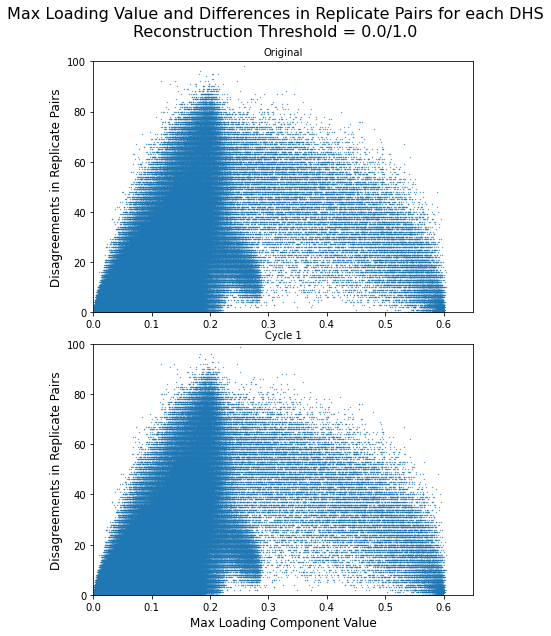

In [73]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

y0 = cycle0_dhs_diff
x0 = dhs_top_loading_val[0, :]
y1 = cycle1_dhs_diff
x1 = dhs_top_loading_val[1, :]

slope0, b_0 = np.polyfit(x0, y0, 1)
slope1, b_1 = np.polyfit(x1, y1, 1)

axes[0].scatter(x0, y0, s=0.1)
axes[1].scatter(x1, y1, s=0.1)
# axes[0].plot(x0, slope0*(x0)+b_0, color='r')
# axes[1].plot(x1, slope1*(x1)+b_1, color='r')
axes[0].set_title('Original', fontsize=10)
axes[1].set_title('Cycle 1', fontsize=10)
axes[0].set_ylim([0, 100])
axes[1].set_ylim([0, 100])
axes[0].set_xlim([0, 0.65])
axes[1].set_xlim([0, 0.65])
    
axes[1].set_ylabel('Disagreements in Replicate Pairs', fontsize=12)
axes[0].set_ylabel('Disagreements in Replicate Pairs', fontsize=12)
axes[1].set_xlabel('Max Loading Component Value', fontsize=12)
plt.suptitle('Max Loading Value and Differences in Replicate Pairs for each DHS\nReconstruction Threshold = 0.0/1.0', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'Mean Signal and Differences in Replicate Pairs for each DHS\nReconstruction Threshold = 0.0/1.0')

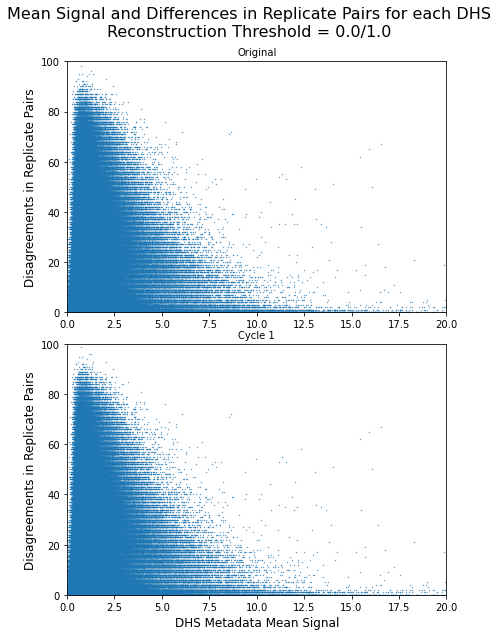

In [61]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

y0 = cycle0_dhs_diff
x0 = dhs_mean_signal
y1 = cycle1_dhs_diff
x1 = dhs_mean_signal

slope0, b_0 = np.polyfit(x0, y0, 1)
slope1, b_1 = np.polyfit(x1, y1, 1)

axes[0].scatter(x0, y0, s=0.1)
axes[1].scatter(x1, y1, s=0.1)
# axes[0].plot(x0, slope0*(x0)+b_0, color='r')
# axes[1].plot(x1, slope1*(x1)+b_1, color='r')
axes[0].set_title('Original', fontsize=10)
axes[1].set_title('Cycle 1', fontsize=10)
axes[0].set_ylim([0, 100])
axes[1].set_ylim([0, 100])
axes[0].set_xlim([0, 20])
axes[1].set_xlim([0, 20])
    
axes[1].set_ylabel('Disagreements in Replicate Pairs', fontsize=12)
axes[0].set_ylabel('Disagreements in Replicate Pairs', fontsize=12)
axes[1].set_xlabel('DHS Metadata Mean Signal', fontsize=12)
plt.suptitle('Mean Signal and Differences in Replicate Pairs for each DHS\nReconstruction Threshold = 0.0/1.0', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'Biosample Presence and Differences in Replicate Pairs for each DHS\nReconstruction Threshold = 0.0/1.0')

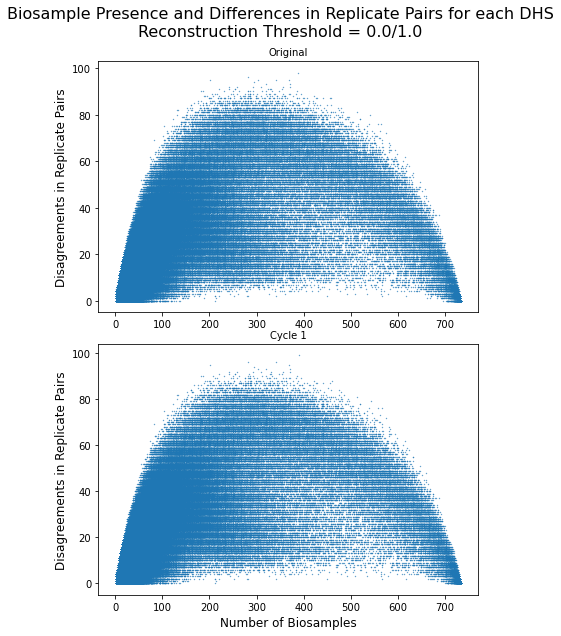

In [62]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

y0 = cycle0_dhs_diff
x0 = cycle0_dhs_biosample_sum
y1 = cycle1_dhs_diff
x1 = cycle1_dhs_biosample_sum

slope0, b_0 = np.polyfit(x0, y0, 1)
slope1, b_1 = np.polyfit(x1, y1, 1)

axes[0].scatter(x0, y0, s=0.1)
axes[1].scatter(x1, y1, s=0.1)
# axes[0].plot(x0, slope0*(x0)+b_0, color='r')
# axes[1].plot(x1, slope1*(x1)+b_1, color='r')
axes[0].set_title('Original', fontsize=10)
axes[1].set_title('Cycle 1', fontsize=10)
# axes[0].set_ylim([0, 10])
# axes[1].set_ylim([0, 10])
    
axes[1].set_ylabel('Disagreements in Replicate Pairs', fontsize=12)
axes[0].set_ylabel('Disagreements in Replicate Pairs', fontsize=12)
axes[1].set_xlabel('Number of Biosamples', fontsize=12)
plt.suptitle('Biosample Presence and Differences in Replicate Pairs for each DHS\nReconstruction Threshold = 0.0/1.0', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'Effect of SPOT Score on Replicate Differences\nReconstruction Threshold = 0.0/1.0')

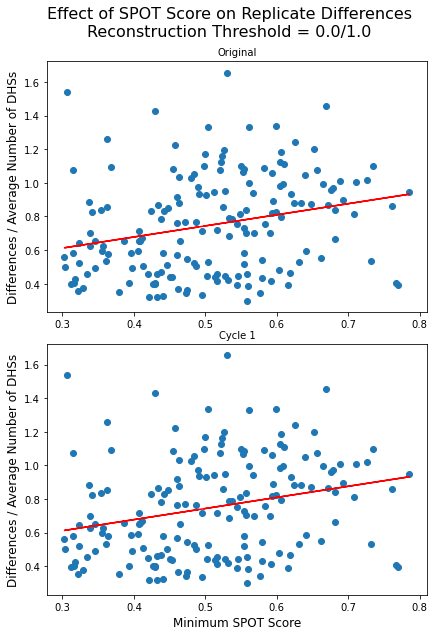

In [46]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

slope0, y_0 = np.polyfit(cycle0_min_spot, cycle0_total_changes/cycle0_total_num_dhss, 1)
slope1, y_1 = np.polyfit(cycle1_min_spot, cycle1_total_changes/cycle1_total_num_dhss, 1)

axes[0].scatter(cycle0_min_spot, cycle0_total_changes/cycle0_total_num_dhss)
axes[1].scatter(cycle1_min_spot, cycle1_total_changes/cycle1_total_num_dhss)
axes[0].plot(cycle0_min_spot, slope0*(cycle0_min_spot)+y_0, color='r')
axes[1].plot(cycle1_min_spot, slope1*(cycle1_min_spot)+y_1, color='r')
axes[0].set_title('Original', fontsize=10)
axes[1].set_title('Cycle 1', fontsize=10)
# axes[0].set_ylim([0, 10])
# axes[1].set_ylim([0, 10])
    

    
axes[1].set_ylabel('Differences / Average Number of DHSs', fontsize=12)
axes[0].set_ylabel('Differences / Average Number of DHSs', fontsize=12)
axes[1].set_xlabel('Minimum SPOT Score', fontsize=12)
plt.suptitle('Effect of SPOT Score on Replicate Differences\nReconstruction Threshold = 0.0/1.0', fontsize=16, x=0.5, y=1.07)

In [18]:
#older function that does not account for pairings with multiple replicates
def test_similarity(dhs_arr=cycle0_dhs_arr.astype(int), repnames_arr=biosamples_repnames, sampnames_arr=biosamples_sampnames):
    total_changes = []
    samp_rep_ind_list = []
    total_num_dhss = []
    for rep_name, rep_ind in zip(repnames_arr, range(len(repnames_arr))):
        if (rep_name!='nan') & (len(np.where(sampnames_arr==rep_name)[0]) == 1): #### change, I need to cast to str and split by ',' so I can handel biosamples with multiple replicates. Might not be this line but somewhere in here 
            samp_ind = np.where(sampnames_arr==rep_name)[0][0]
            if tuple(np.sort(np.array([rep_ind, samp_ind]))) not in samp_rep_ind_list:
#                 print(rep_ind, samp_ind)
                samp_rep_ind_list.append(tuple(np.sort(np.array([rep_ind, samp_ind]))))
                changes = np.sum(np.abs(dhs_arr[rep_ind, :] - dhs_arr[samp_ind, :]))
                total_changes.append(changes)
                #average number of DHSs for replicate biosample
                num_dhss = np.mean([np.sum(dhs_arr[rep_ind, :]), np.sum(dhs_arr[samp_ind, :])])
                total_num_dhss.append(num_dhss)
    total_changes = np.array(total_changes)
    total_num_dhss = np.array(total_num_dhss)
    
    average_changes = np.mean(total_changes)
    print(average_changes)
    return total_changes, total_num_dhss

cycle0_total_changes, cycle0_total_num_dhss = test_similarity(cycle0_dhs_int_arr)
cycle1_total_changes, cycle1_total_num_dhss = test_similarity(cycle1_dhs_int_arr)

99262.1616766467
99274.05988023953


In [21]:
cycle0_percent_changes = cycle0_total_changes/cycle0_total_num_dhss
cycle1_percent_changes = cycle1_total_changes/cycle1_total_num_dhss

Text(0.5, 1.07, 'Number of Differences Between Biosample Replicates\nReconstruction Threshold Flip, Threshold=0.0/1.0')

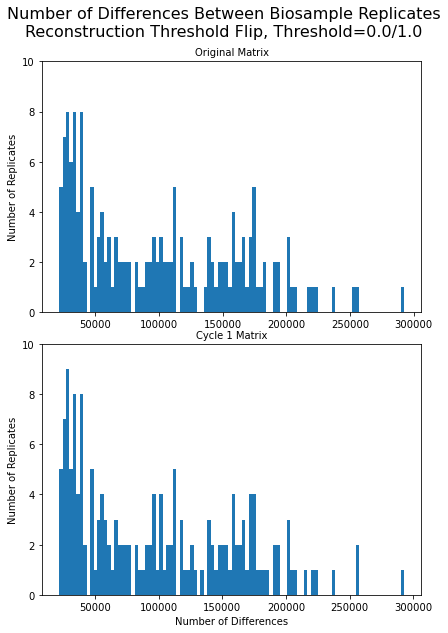

In [38]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()


axes[0].hist(cycle0_total_changes, bins=100)
axes[1].hist(cycle1_total_changes, bins=100)
axes[0].set_title('Original Matrix', fontsize=10)
axes[1].set_title('Cycle 1 Matrix', fontsize=10)
axes[0].set_ylim([0, 10])
axes[1].set_ylim([0, 10])
    

    
axes[1].set_xlabel('Number of Differences')
axes[0].set_ylabel('Number of Replicates')
axes[1].set_ylabel('Number of Replicates')
plt.suptitle('Number of Differences Between Biosample Replicates\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'Number of Differences/Number of DHSs Between Biosample Replicates\nReconstruction Threshold Flip, Threshold=0.0/1.0')

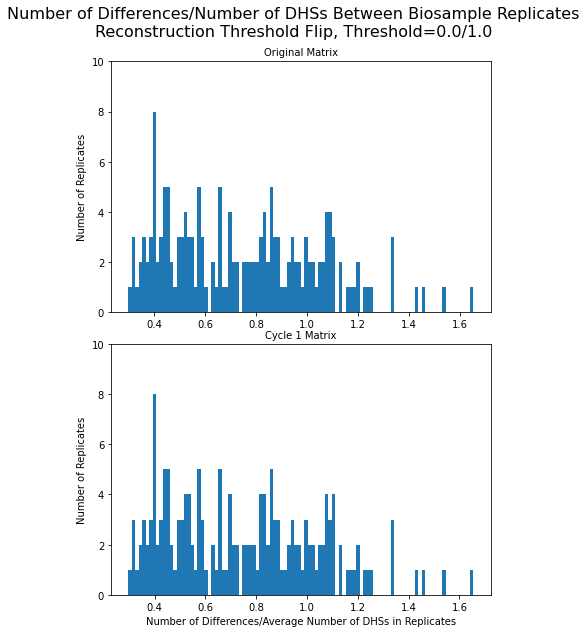

In [37]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes[0].hist(cycle0_percent_changes, bins=100)
axes[1].hist(cycle1_percent_changes, bins=100)
axes[0].set_title('Original Matrix', fontsize=10)
axes[1].set_title('Cycle 1 Matrix', fontsize=10)

axes[0].set_ylim([0, 10])
axes[1].set_ylim([0, 10])
  
axes[1].set_xlabel('Number of Differences/Average Number of DHSs in Replicates')
axes[0].set_ylabel('Number of Replicates')
axes[1].set_ylabel('Number of Replicates')
plt.suptitle('Number of Differences/Number of DHSs Between Biosample Replicates\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

In [55]:
def random_similarity(dhs_arr, iterations):
    total_changes = []
    for i in range(iterations):
        biosample1 = random.randrange(733)
        biosample2 = random.randrange(733)
        while biosample1==biosample2:
            biosample2 = random.randrange(733)
        changes = np.sum(np.abs(dhs_arr[biosample1, :] - dhs_arr[biosample2, :]))
        total_changes.append(changes)
    total_changes = np.array(total_changes)
    
    average_changes = np.mean(total_changes)
    print(average_changes)
    return total_changes

In [74]:
random_changes = random_similarity(cycle0_dhs_int_arr, 167)

138637.7724550898


In [78]:
number_call_per_biosample = np.sum(cycle0_dhs_int_arr, axis=1)
np.mean(number_call_per_biosample)

104062.1241473397

**Replicate Sanity Check**

In [16]:
for i in range(len(biosamples_repnames)):
    rep = biosamples_repnames[i]
    if rep!='nan':
        samp_ind = np.where(biosamples_sampnames==rep)[0]
        if len(samp_ind)>0:
            samp_ind = samp_ind[0]
            samp_rep = biosamples_repnames[samp_ind]
            samp_rep_ind = np.where(biosamples_sampnames==samp_rep)[0]
            if len(samp_rep_ind)>0:
                samp_rep_ind = samp_rep_ind[0]
                if samp_rep_ind!=i:
                    print(samp_rep_ind, i)

In [67]:
total_changes = []
samp_rep_ind_list = []
count=0
tup_count=0
tup_list = []
for rep_name, rep_ind in zip(biosamples_repnames, range(len(biosamples_repnames))):
    if rep_name!='nan':
        if len(np.where(biosamples_sampnames==rep_name)[0]) == 1:
            samp_ind = np.where(biosamples_sampnames==rep_name)[0][0]
            if tuple(np.sort(np.array([rep_ind, samp_ind]))) not in samp_rep_ind_list:
                samp_rep_ind_list.append(tuple(np.sort(np.array([rep_ind, samp_ind]))))
                changes = np.sum(np.abs(cycle0_dhs_int_arr[rep_ind, :] - cycle0_dhs_int_arr[samp_ind, :]))
                total_changes.append(changes)
            else:
                tup_count+=1
                tup_list.append(tuple(np.sort(np.array([rep_ind, samp_ind]))))
        else:
            count+=1
total_changes = np.array(total_changes)
print(total_changes.shape)
average_changes = np.mean(total_changes)

(167,)


In [70]:
for i in samp_rep_ind_list:
    if i not in tup_list:
        print(i)

(56, 158)


In [66]:
tup_count

166

In [76]:
biosample_df.loc[[36, 37]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
36,37,HGF,NaN,ENCSR000ENS,ENCLB486ZZZ,ENCBS786ANZ,AG4192,LN2304,DS11738,DS11752,...,minElute,80.0,5.6,NaN,NaN,2009-08-05,22293070,0.4847,63915,63851
37,38,HGF,NaN,ENCSR000ENS,ENCLB487ZZZ,ENCBS310AAA,AG4191,LN2307,DS11752,DS11738,...,minElute,60.0,9.8,NaN,NaN,2009-08-05,351870884,0.4918,200730,200524


In [71]:
biosample_df.loc[[56, 158]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
56,57,CD34,Myeloid / erythroid,ENCSR191EII,ENCLB262HGC,ENCBS912YBQ,AG9156,LN2482,DS12274,DS14197,...,minElute,80.0,18.5,NaN,NaN,NaN,211609789,0.6518,196198,195691
158,159,CD34,NaN,ENCSR191EII,ENCLB323HYV,ENCBS912YBQ,AG9136,LN2999,DS14197,nan,...,minElute,160.0,8.1,6300000.0,Buffer A,NaN,24389674,0.6518,52106,52010


In [77]:
count + 167*2 - 1

349

In [31]:
biosamples_repnames[biosamples_repnames!='nan'].shape

(349,)